In [454]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**Task 1: Data Understanding & Exploration**

In [455]:
df = pd.read_csv('/content/drive/MyDrive/Data Science Main/EXAM/G2.csv')

In [456]:
df.shape

(1351, 10)

In [457]:
df.head()

,id,name,height_dm,weight_hg,base_experience,type_1,type_2,hp,attack,defense
0,1,bulbasaur,7,69,64.0,grass,poison,45,49,49
1,2,ivysaur,10,130,142.0,grass,poison,60,62,63
2,3,venusaur,20,1000,236.0,grass,poison,80,82,83
3,4,charmander,6,85,62.0,fire,NaN,39,52,43
4,5,charmeleon,11,190,142.0,fire,NaN,58,64,58


In [458]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1351 entries, 0 to 1350
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               1351 non-null   int64  
 1   name             1351 non-null   object 
 2   height_dm        1351 non-null   int64  
 3   weight_hg        1351 non-null   int64  
 4   base_experience  1302 non-null   float64
 5   type_1           1351 non-null   object 
 6   type_2           765 non-null    object 
 7   hp               1351 non-null   int64  
 8   attack           1351 non-null   int64  
 9   defense          1351 non-null   int64  
dtypes: float64(1), int64(6), object(3)
memory usage: 105.7+ KB


In [459]:
df.describe()

,id,height_dm,weight_hg,base_experience,hp,attack,defense
count,1351.000000,1351.000000,1351.000000,1302.000000,1351.000000,1351.000000,1351.000000
mean,2841.692080,20.443375,991.059956,161.943932,71.673575,82.757957,76.193930
std,4139.019112,53.238467,1953.115812,82.532554,26.827529,32.351906,30.712902
min,1.000000,1.000000,0.000000,36.000000,1.000000,5.000000,5.000000
25%,338.500000,6.000000,94.500000,71.000000,55.000000,60.000000,55.000000
50%,676.000000,11.000000,326.000000,165.000000,70.000000,80.000000,70.000000
75%,1013.500000,17.000000,853.500000,222.500000,85.000000,102.500000,95.000000
max,10326.000000,1000.000000,10000.000000,608.000000,255.000000,190.000000,250.000000


In [460]:
numerical_cols = df.select_dtypes(
    include=np.number
).columns.tolist()
print("Number of numerical columns:", len(numerical_cols))

Number of numerical columns: 7


In [461]:
categorical_cols = df.select_dtypes(
    exclude=np.number
).columns.tolist()
print("Number of categorical columns:", len(categorical_cols))

Number of categorical columns: 3


In [462]:
no_of_missing_values = df.isnull().sum()
print("Number of missing values in each column:")
print(no_of_missing_values)

Number of missing values in each column:
id                   0
name                 0
height_dm            0
weight_hg            0
base_experience     49
type_1               0
type_2             586
hp                   0
attack               0
defense              0
dtype: int64


In [463]:
duplicate_count = df.duplicated().sum()
print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [464]:
unique_df = pd.DataFrame({
    'Column': df.columns,
    'Unique Values': [
        df[col].nunique()
        for col in df.columns
    ]
})

unique_df

,Column,Unique Values
0,id,1351
1,name,1351
2,height_dm,86
3,weight_hg,551
4,base_experience,201
5,type_1,18
6,type_2,18
7,hp,109
8,attack,131
9,defense,120


In [465]:
feature_summary = pd.DataFrame({
    'Data Type': df.dtypes,
    'Unique Values': df.nunique(),
    'Missing NaN': df.isnull().sum(),
    'Duplicate': df.duplicated().sum(),
    'Describe': df.describe().loc['mean'],
    'Describe': df.describe().loc['std'],
    'Describe': df.describe().loc['min'],
    'Describe': df.describe().loc['max'],
})
feature_summary

,Data Type,Unique Values,Missing NaN,Duplicate,Describe
attack,int64,131,0,0,190.0
base_experience,float64,201,49,0,608.0
defense,int64,120,0,0,250.0
height_dm,int64,86,0,0,1000.0
hp,int64,109,0,0,255.0
id,int64,1351,0,0,10326.0
name,object,1351,0,0,NaN
type_1,object,18,0,0,NaN
type_2,object,18,586,0,NaN
weight_hg,int64,551,0,0,10000.0


In [466]:
print(df['type_1'].value_counts())

type_1
water       160
normal      139
grass       122
electric    100
bug          95
psychic      86
fire         84
rock         83
dark         63
fighting     62
dragon       59
steel        52
poison       52
ghost        52
ground       50
ice          44
fairy        35
flying       13
Name: count, dtype: int64


In [467]:
print(df['type_2'].value_counts())

type_2
flying      141
dragon       58
psychic      56
poison       54
fairy        53
steel        47
fighting     47
ground       46
ghost        44
dark         36
grass        34
water        32
fire         25
ice          25
rock         21
normal       21
electric     14
bug          11
Name: count, dtype: int64


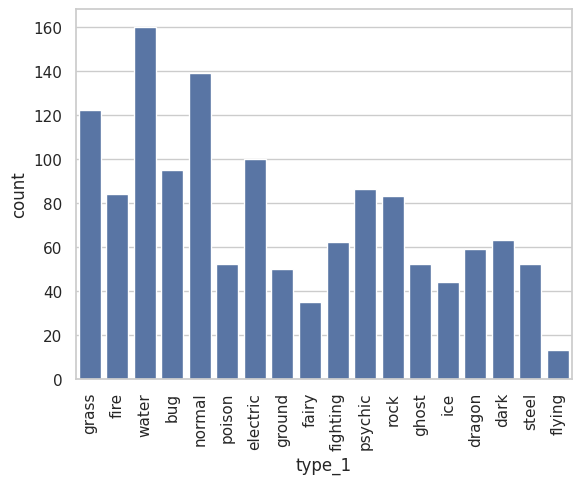

In [468]:
sns.countplot(data=df, x='type_1')
plt.xticks(rotation=90)
plt.show()

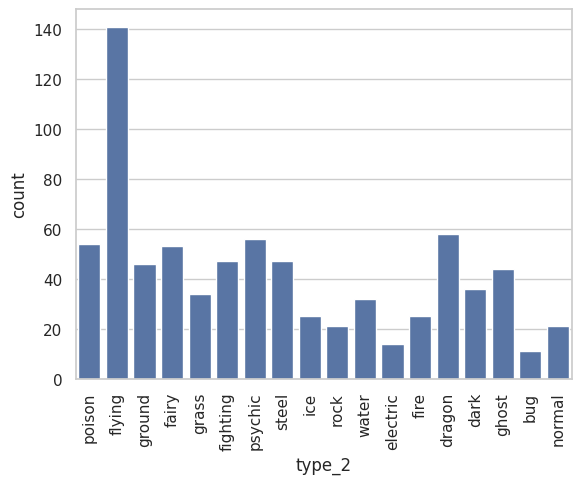

In [469]:
sns.countplot(data=df, x='type_2')
plt.xticks(rotation=90)
plt.show()

Answers of Analytical Questions

1. Water type pokemon appears most frequently in the dataset in type_1 but in type_2 flying type pokemon is the most frequently appearing pokemon type

2. The weight_hg feature shows the greatest variation among the pokemon

3. My initial observations about the dataset is it contains 1351 rows and 10 columns which 7 of them are numerical and 3 are categorical features. the base_experience has 49 missing values and type_2 has 586 missing values and there are no duplicate values

**Task 2: Data Preprocessing**

In [470]:
df.drop(columns=['id'], inplace=True)

In [471]:
df.drop(columns=['name'], inplace=True)

In [472]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1351 entries, 0 to 1350
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   height_dm        1351 non-null   int64  
 1   weight_hg        1351 non-null   int64  
 2   base_experience  1302 non-null   float64
 3   type_1           1351 non-null   object 
 4   type_2           765 non-null    object 
 5   hp               1351 non-null   int64  
 6   attack           1351 non-null   int64  
 7   defense          1351 non-null   int64  
dtypes: float64(1), int64(5), object(2)
memory usage: 84.6+ KB


In [473]:
df['base_experience'].fillna(df['base_experience'].median(), inplace=True)

/tmp/ipykernel_1086/711206339.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['base_experience'].fillna(df['base_experience'].median(), inplace=True)


In [474]:
df["type_2"] = df["type_2"].replace(r"^\s*$", pd.NA, regex=True).fillna("None")

In [475]:
df.isnull().sum()

,0
height_dm,0
weight_hg,0
base_experience,0
type_1,0
type_2,0
hp,0
attack,0
defense,0


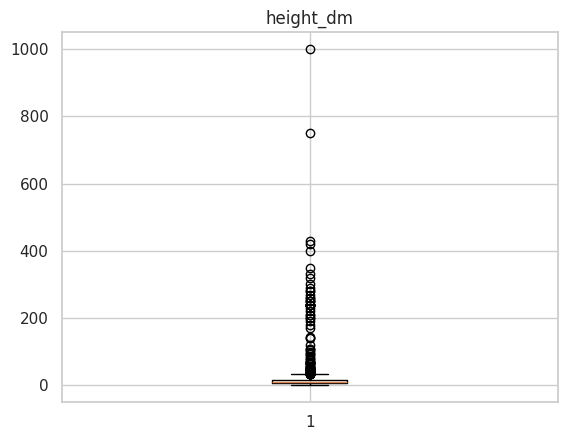

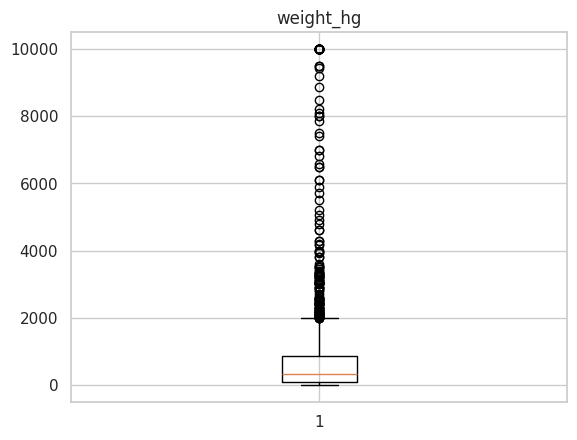

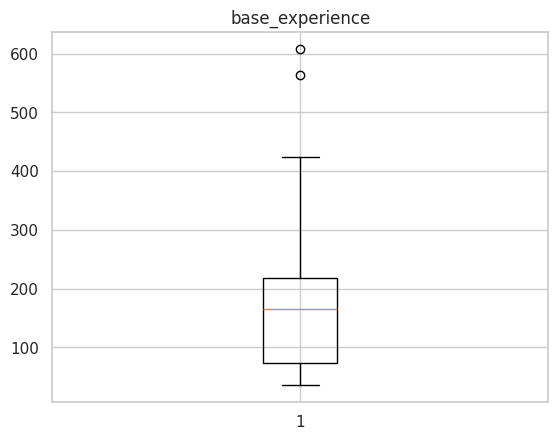

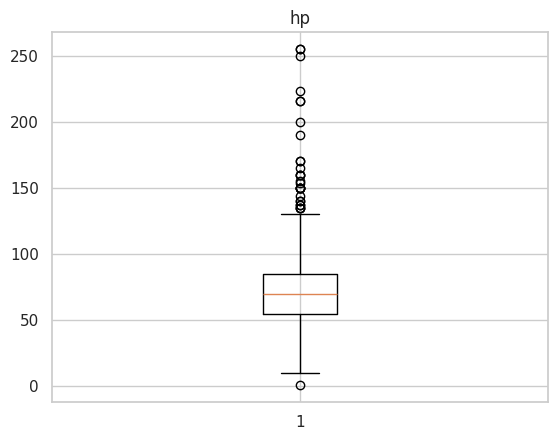

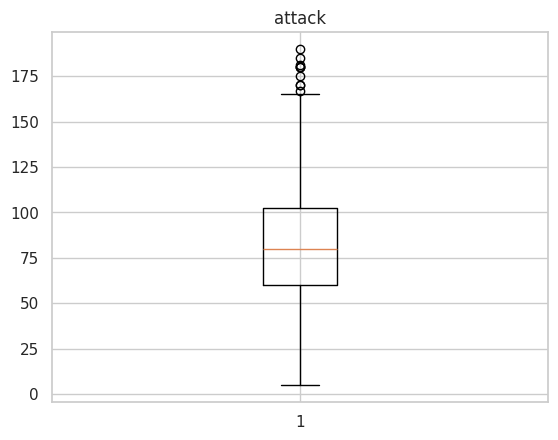

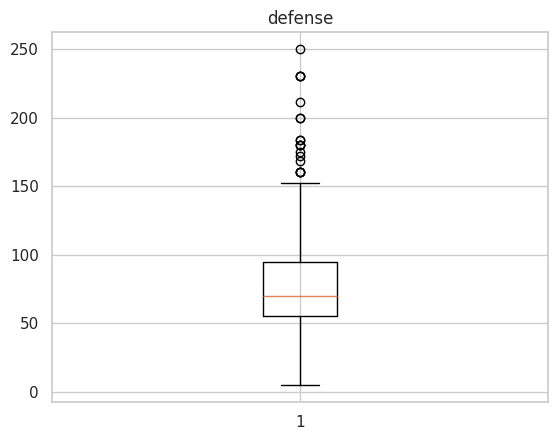

In [476]:
columns = df.select_dtypes(include=['number']).columns
for i in columns:
  plt.boxplot(df[i])
  plt.title(i)
  plt.show()

In [477]:
df.drop(columns=['type_2'], inplace=True)

**Since there is only type_1 which is the target class as categorical variables we dont need to do the encoding**

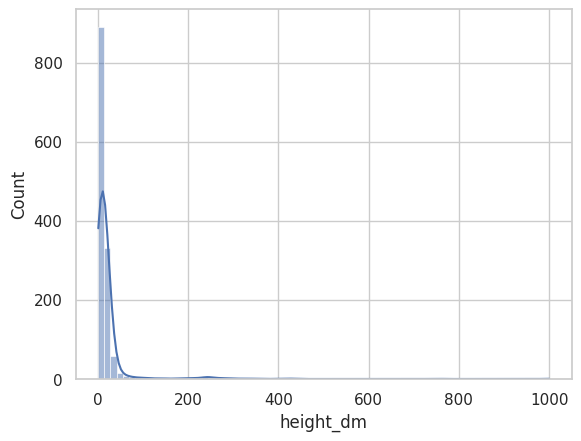

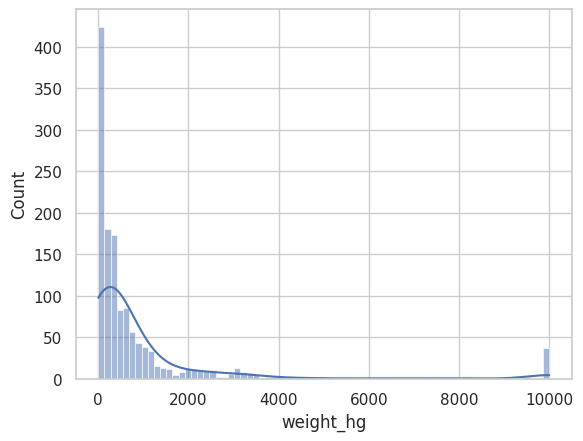

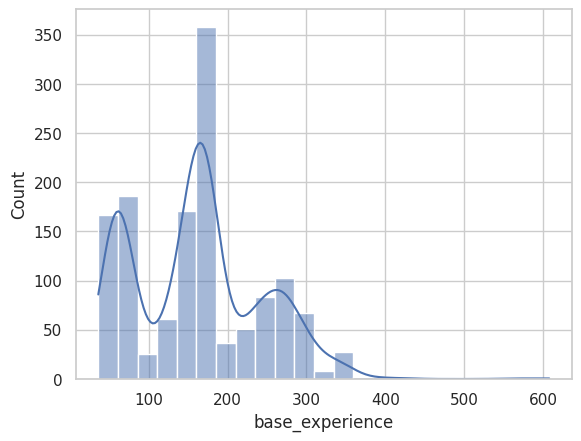

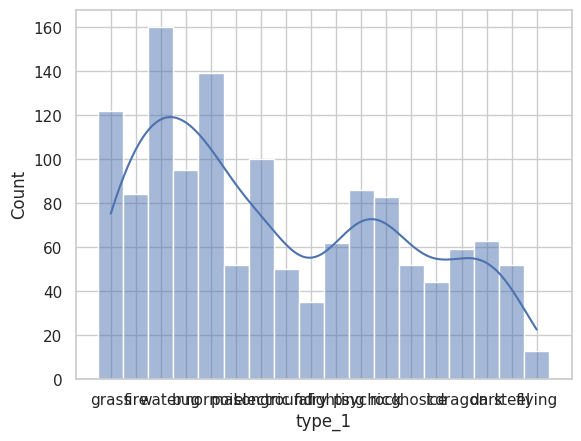

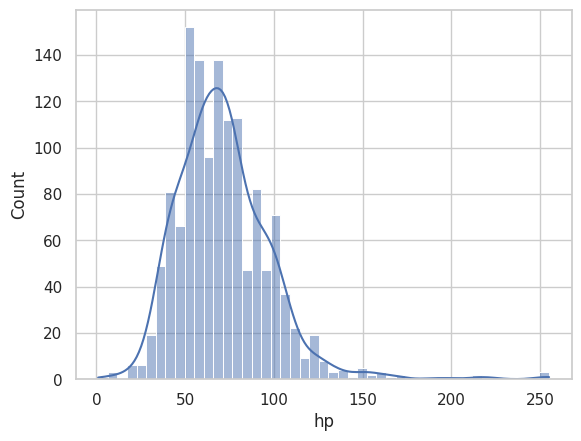

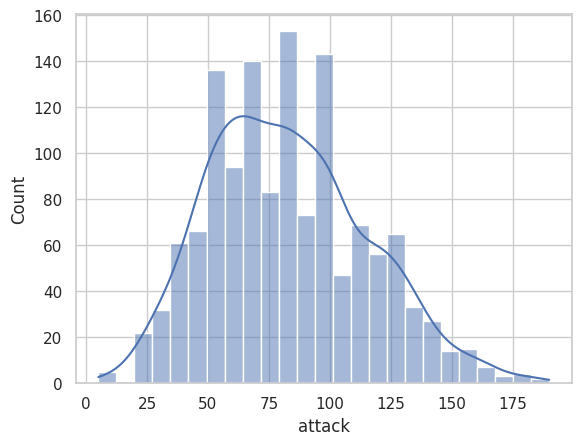

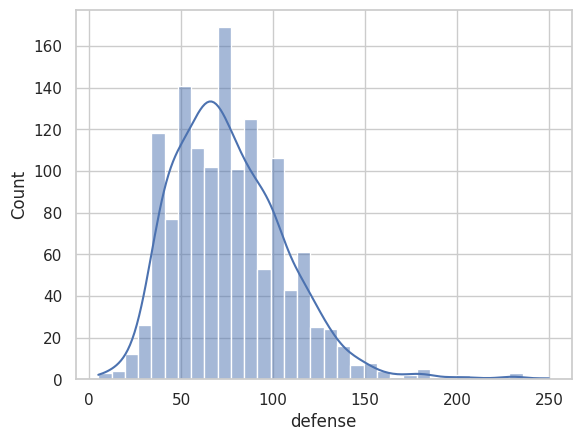

In [478]:
for i in df.columns:
  sns.histplot(df[i],kde=True)
  plt.show()

In [479]:
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
print("Number of numerical columns:", len(numerical_cols))


Number of numerical columns: 6


In [480]:
from sklearn.model_selection import train_test_split
x = df.drop(columns=['type_1'])
y = df['type_1']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
print(x_train.shape,x_test.shape,y_train.shape,y_test.shape)

(1080, 6) (271, 6) (1080,) (271,)


In [481]:
# from sklearn.utils import class_weight
# class_weights = class_weight.compute_class_weight(
#     class_weight='balanced',
#     classes=np.unique(y_train),
#     y=y_train
# )

In [482]:
# apply moderaely balanced class weight in training data
class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

In [483]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
x_train_resampled = scaler.fit_transform(x_train)

Answers for the Anaytical Questions

1. To make the inputs consistent and usable by the model and for better understanding of the datas by the model for example, handle missing values and convert categorical inputs to numbers.

Here the features such as id, name, type_2 are not necessary for predicting the type_1 battle type of pokemon so we should remove it after that the only categorical variable is the target class itself so there is no need of encoding any columns

2. We should handle the missing values in type_2 by filling it with 'None'. In type_2 the missing values means there is no secondary battle type for that particular pokemon so we should fill it with 'None'
but type_2 is removed because for predicting the primary battle type we dont need the secondary battle type feature

**Task 3: Exploratry Data Analysis**

Attack vs Defence

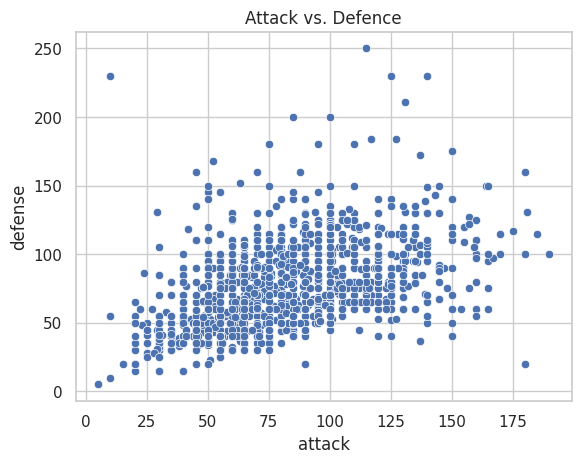

In [484]:
sns.scatterplot(data=df, x="attack", y="defense")
plt.title("Attack vs. Defence")
plt.show()

HP distribution across Pokemon types

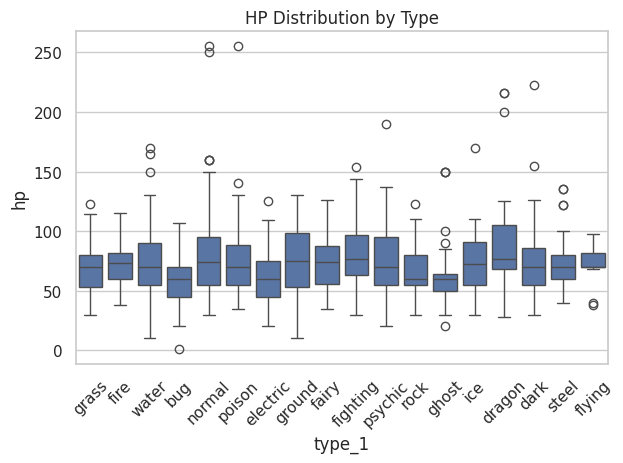

In [485]:
sns.boxplot(data=df, x="type_1", y="hp")
plt.title("HP Distribution by Type")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Base experience by type

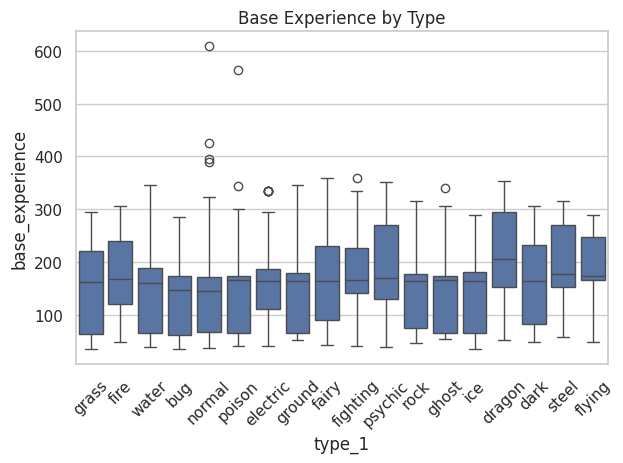

In [486]:
plot_df = df.dropna(subset=["base_experience"])
sns.boxplot(data=plot_df, x="type_1", y="base_experience")
plt.title("Base Experience by Type")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Height vs Weight

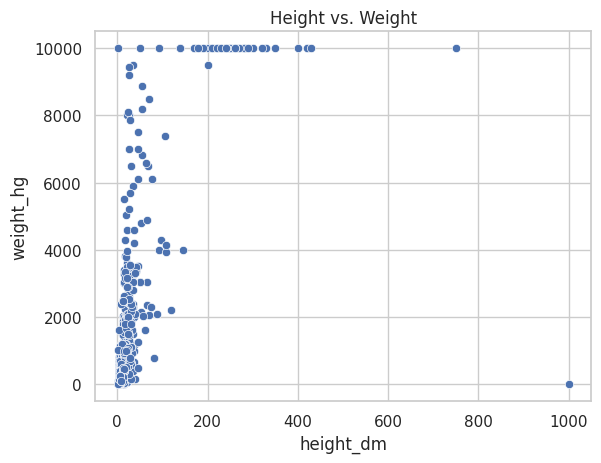

In [487]:
sns.scatterplot(data=df, x="height_dm", y="weight_hg")
plt.title("Height vs. Weight")
plt.show()

Answers for the Analytical Questions

1. Fighting Pokemon tends to have the highest average attack.

2. Yes there is a relationship between height and weight.Taller Pokemon tends to weigh more

3. Defense and attack show the strongest differences between types in this dataset.

**Task 4: Machine Learning Model**

Logistic Regression

In [488]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

model = LogisticRegression(max_iter=3000, random_state=42)
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Weighted Precision:", precision_score(y_test, y_pred, average="weighted", zero_division=0))
print("Weighted Recall:", recall_score(y_test, y_pred, average="weighted", zero_division=0))
print("Weighted F1 Score:", f1_score(y_test, y_pred, average="weighted", zero_division=0))
print("Macro F1 Score:", f1_score(y_test, y_pred, average="macro", zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.15129151291512916
Weighted Precision: 0.09869187652346784
Weighted Recall: 0.15129151291512916
Weighted F1 Score: 0.10724569563033827
Macro F1 Score: 0.08022553461295666
Confusion Matrix:
 [[ 0  0  0  2  1  1  1  0  0  0  0  0  3  0  1  2  2  6]
 [ 0  0  0  0  0  1  0  0  0  1  0  0  4  0  2  1  0  4]
 [ 0  0  1  1  0  1  1  0  0  0  0  0  1  0  2  1  0  4]
 [ 0  0  0  6  0  2  0  0  0  1  0  0  3  0  1  1  1  5]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  4  0  1  0  0  2]
 [ 0  0  0  0  0  0  0  0  0  1  0  0  4  0  0  2  0  5]
 [ 0  0  0  3  0  0  0  0  0  0  0  0  5  0  1  2  0  6]
 [ 0  0  0  2  0  0  0  0  0  0  0  0  1  0  0  0  0  0]
 [ 1  0  0  2  0  0  0  0  0  1  0  0  1  0  0  1  1  3]
 [ 1  0  0  6  0  1  0  0  0  1  0  0  1  0  1  2  1 11]
 [ 1  0  0  1  0  2  0  0  0  0  0  0  2  0  0  1  0  3]
 [ 0  0  0  1  0  1  0  0  0  0  0  0  1  0  1  0  0  5]
 [ 0  0  0  0  0  1  0  0  0  2  1  0 12  0  0  0  0 12]
 [ 0  0  0  0  0  0  0  0  0  1  0  0  2  0  0  1  0  6]
 

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Random Forest

In [489]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

model = RandomForestClassifier(n_estimators=300, random_state=42)
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Weighted Precision:", precision_score(y_test, y_pred, average="weighted", zero_division=0))
print("Weighted Recall:", recall_score(y_test, y_pred, average="weighted", zero_division=0))
print("Weighted F1 Score:", f1_score(y_test, y_pred, average="weighted", zero_division=0))
print("Macro F1 Score:", f1_score(y_test, y_pred, average="macro", zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.2878228782287823
Weighted Precision: 0.2904026805502821
Weighted Recall: 0.2878228782287823
Weighted F1 Score: 0.28226534332375675
Macro F1 Score: 0.24769188120653174
Confusion Matrix:
 [[ 8  0  1  0  1  1  1  0  0  2  1  0  0  1  1  1  0  1]
 [ 1  2  0  1  1  0  0  0  0  1  0  2  3  0  0  0  0  2]
 [ 0  0  4  1  0  0  0  0  0  0  0  0  1  1  0  1  1  3]
 [ 0  1  0  8  0  0  1  0  0  2  0  0  1  1  0  0  1  5]
 [ 1  0  0  0  0  1  0  0  1  2  0  0  1  0  0  0  0  1]
 [ 1  1  0  0  0  2  0  0  0  1  0  0  2  1  0  1  0  3]
 [ 2  0  1  1  0  0  4  0  0  1  0  1  3  0  2  0  1  1]
 [ 0  0  0  1  0  0  1  0  0  1  0  0  0  0  0  0  0  0]
 [ 2  0  0  0  0  0  0  0  2  1  0  0  0  0  3  0  1  1]
 [ 3  0  1  1  0  0  2  0  0  6  0  0  1  0  3  2  0  6]
 [ 1  1  0  0  0  1  0  0  0  1  2  0  0  0  0  2  0  2]
 [ 2  0  0  0  0  0  3  0  0  0  1  0  3  0  0  0  0  0]
 [ 0  2  1  1  0  1  3  0  1  2  0  0 13  0  0  0  0  4]
 [ 0  0  1  0  0  0  0  0  1  0  0  0  0  2  0  0  1  5]
 [ 0

KNN

In [490]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

model = KNeighborsClassifier(n_neighbors=5)
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Weighted Precision:", precision_score(y_test, y_pred, average="weighted", zero_division=0))
print("Weighted Recall:", recall_score(y_test, y_pred, average="weighted", zero_division=0))
print("Weighted F1 Score:", f1_score(y_test, y_pred, average="weighted", zero_division=0))
print("Macro F1 Score:", f1_score(y_test, y_pred, average="macro", zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.17343173431734318
Weighted Precision: 0.16336934080864443
Weighted Recall: 0.17343173431734318
Weighted F1 Score: 0.1579946135249333
Macro F1 Score: 0.1399602521493696
Confusion Matrix:
 [[9 0 1 1 1 1 1 0 0 1 0 0 2 1 0 0 1 0]
 [1 4 1 0 1 1 0 0 0 2 0 0 0 0 0 1 0 2]
 [1 0 3 0 0 2 0 0 0 0 0 0 1 0 1 0 1 3]
 [2 1 0 7 1 1 0 1 0 0 0 0 4 0 1 0 1 1]
 [1 0 0 0 1 0 0 0 0 1 0 0 1 0 1 0 0 2]
 [2 1 2 0 0 2 0 0 0 1 0 0 3 0 0 1 0 0]
 [2 2 0 0 1 0 4 0 0 4 0 1 1 0 0 0 1 1]
 [0 1 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0]
 [2 0 0 1 0 1 0 0 2 0 0 0 0 0 1 1 0 2]
 [4 1 1 2 0 0 5 0 2 4 0 0 1 2 1 1 0 1]
 [1 2 0 1 0 1 0 0 0 0 0 0 1 0 0 2 1 1]
 [3 0 1 0 0 0 2 0 0 0 0 0 2 0 0 1 0 0]
 [2 7 1 4 0 0 5 0 0 3 0 0 4 0 1 0 0 1]
 [1 1 0 0 0 2 1 0 0 1 0 0 0 0 0 1 0 3]
 [4 2 3 3 0 1 1 0 0 1 0 0 0 0 1 0 0 1]
 [1 2 1 2 0 2 1 0 0 0 0 0 0 0 0 3 0 5]
 [2 1 2 0 0 1 0 0 0 0 0 0 1 1 1 0 0 1]
 [8 1 3 0 0 2 2 1 0 4 0 1 3 2 0 0 2 3]]
Classification Report:
               precision    recall  f1-score   support

         bug       

Desicion Tree

In [491]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

model = DecisionTreeClassifier(random_state=42)
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Weighted Precision:", precision_score(y_test, y_pred, average="weighted", zero_division=0))
print("Weighted Recall:", recall_score(y_test, y_pred, average="weighted", zero_division=0))
print("Weighted F1 Score:", f1_score(y_test, y_pred, average="weighted", zero_division=0))
print("Macro F1 Score:", f1_score(y_test, y_pred, average="macro", zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.1918819188191882
Weighted Precision: 0.1966028890200498
Weighted Recall: 0.1918819188191882
Weighted F1 Score: 0.18955785077777607
Macro F1 Score: 0.16683639256160676
Confusion Matrix:
 [[5 1 0 1 0 0 1 0 0 1 2 3 1 0 1 2 1 0]
 [0 2 0 1 1 0 0 0 0 0 0 0 2 1 1 1 1 3]
 [0 0 2 4 1 1 0 0 0 0 1 0 1 0 0 2 0 0]
 [0 0 1 9 0 0 3 0 0 3 0 0 0 1 1 0 1 1]
 [0 0 0 0 1 2 0 0 0 2 0 0 0 1 1 0 0 0]
 [1 1 0 1 0 1 1 0 1 0 0 0 2 1 0 2 1 0]
 [1 0 0 0 1 1 2 1 0 3 0 1 2 0 1 0 1 3]
 [0 0 0 1 0 0 1 0 0 1 0 0 0 0 0 0 0 0]
 [2 0 0 0 0 0 0 0 2 0 1 1 0 0 2 1 0 1]
 [4 0 1 3 1 0 1 0 1 5 2 0 1 1 2 1 1 1]
 [2 1 0 1 0 0 0 0 0 0 2 0 1 0 0 2 0 1]
 [0 0 0 1 0 0 2 0 0 1 1 0 0 0 2 0 0 2]
 [0 4 1 2 0 1 4 0 0 0 1 0 7 1 3 1 0 3]
 [1 1 0 0 1 0 1 0 0 1 1 0 1 1 0 0 0 2]
 [0 0 1 2 2 0 2 0 0 0 0 0 0 1 3 0 1 5]
 [1 0 0 1 0 0 1 0 1 2 0 0 3 0 0 5 0 3]
 [1 1 0 0 0 0 2 0 0 0 0 0 0 0 0 3 1 2]
 [3 0 1 1 1 0 5 0 0 4 3 1 1 2 2 2 2 4]]
Classification Report:
               precision    recall  f1-score   support

         bug       0

XG boost

In [453]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

# Encode target labels for XGBoost
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

# Give less common training classes more weight
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train_encoded
)

model = XGBClassifier(
    objective="multi:softprob",
    num_class=len(label_encoder.classes_),
    eval_metric="mlogloss",
    n_estimators=600,
    learning_rate=0.03,
    max_depth=4,
    min_child_weight=2,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    tree_method="hist",
    random_state=42
)

model.fit(x_train, y_train_encoded, sample_weight=sample_weights)

y_pred_encoded = model.predict(x_test).astype(int)
y_pred = label_encoder.inverse_transform(y_pred_encoded)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Weighted Precision:", precision_score(y_test, y_pred, average="weighted", zero_division=0))
print("Weighted Recall:", recall_score(y_test, y_pred, average="weighted", zero_division=0))
print("Weighted F1 Score:", f1_score(y_test, y_pred, average="weighted", zero_division=0))
print("Macro F1 Score:", f1_score(y_test, y_pred, average="macro", zero_division=0))

class_names = label_encoder.classes_
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred, labels=class_names))
print(
    "Classification Report:\n",
    classification_report(
        y_test,
        y_pred,
        labels=class_names,
        target_names=class_names,
        zero_division=0
    )
)

Accuracy: 0.2952029520295203
Weighted Precision: 0.3180923023827001
Weighted Recall: 0.2952029520295203
Weighted F1 Score: 0.29678578166859054
Macro F1 Score: 0.28677184171835357
Confusion Matrix:
 [[ 8  0  1  0  2  1  1  0  1  1  0  0  0  1  1  1  1  0]
 [ 4  4  0  0  2  0  1  1  0  0  0  1  0  0  0  0  0  0]
 [ 0  0  4  1  0  0  0  0  0  0  0  1  1  0  0  1  1  3]
 [ 2  1  0  7  0  1  4  0  0  1  0  1  1  0  0  0  1  1]
 [ 0  0  0  1  2  0  0  0  0  1  0  1  0  1  0  0  0  1]
 [ 2  1  1  0  0  3  0  0  0  1  0  1  1  1  0  1  0  0]
 [ 1  0  0  1  0  0  3  0  1  1  0  2  4  0  2  0  1  1]
 [ 0  0  0  1  0  0  0  0  0  2  0  0  0  0  0  0  0  0]
 [ 1  0  0  0  0  0  0  0  4  0  0  0  0  0  3  1  0  1]
 [ 2  0  0  1  1  0  2  0  0  5  0  1  1  3  3  2  1  3]
 [ 0  1  0  0  0  0  0  0  1  0  3  1  0  0  0  2  0  2]
 [ 1  0  0  1  0  0  2  0  0  1  0  2  2  0  0  0  0  0]
 [ 1  3  1  1  0  2  4  0  1  1  0  0 12  1  0  0  0  1]
 [ 0  1  0  0  0  1  0  0  1  0  0  0  1  1  0  0  1  4]
 [ 0

In [495]:
import joblib
from google.colab import files

file_name = "pokemon_type_xgboost.joblib"

joblib.dump(
    {"model": model, "label_encoder": label_encoder},
    file_name
)

files.download(file_name)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Answers for the Analysis questions

1. XG boost model achieved te best perfromanceBecause it has the hihest macro f1 score which is the average f1 score of each class

2. flying type is the most frequently misclassified type

3. for some pokemon types there are only fewer training samples which makes the model difficult to predict

TASK 5

Answers

1. For game developers: It could help explore how stats relate to types, suggest candidate types for a new character during early design
For players: It could make a best-guess type prediction for an unfamiliar Pokémon based on its height, weight, HP, attack, and defense.

2. predictions are uncertain
it uses limited iinputs

some types have fewer examples
